In [4]:
import os
import pandas as pd
import numpy as np
import SimpleITK as sitk
import torch
from tqdm import tqdm

# 📂 Paths
RESAMPLED_DIR = r"C:\Users\mahdi\OneDrive\Desktop\project\preprocessed\resampled"  # Your resampled CT scans
ANNOTATIONS_PATH = r"C:\Users\mahdi\OneDrive\Desktop\project\data\annotations.csv"
CANDIDATES_PATH = r"C:\Users\mahdi\OneDrive\Desktop\project\data\candidates.csv"
PATCH_OUTPUT_DIR = r"C:\Users\mahdi\OneDrive\Desktop\project\preprocessed\nodules_patches"

# 📂 Create output folders
true_dir = os.path.join(PATCH_OUTPUT_DIR, "true_nodules")
false_dir = os.path.join(PATCH_OUTPUT_DIR, "false_nodules")
os.makedirs(true_dir, exist_ok=True)
os.makedirs(false_dir, exist_ok=True)

# 📋 Parameters
patch_size = 64  # 64x64x64 patches
radius_threshold = 6  # Distance threshold (mm)

# 📚 Load annotations and candidates
annotations = pd.read_csv(ANNOTATIONS_PATH)
candidates = pd.read_csv(CANDIDATES_PATH)

# ❗ Filter only candidates where candidate_label == 1
candidates = candidates[candidates['class'] == 1]

# Helper: world to voxel
def world_to_voxel(world, origin, spacing):
    return np.round((world - origin) / spacing).astype(int)

# Helper: safe patch extraction
def extract_patch(img_array, center_voxel, patch_size):
    half = patch_size // 2
    z, y, x = center_voxel

    z_min = max(z - half, 0)
    y_min = max(y - half, 0)
    x_min = max(x - half, 0)

    z_max = min(z_min + patch_size, img_array.shape[0])
    y_max = min(y_min + patch_size, img_array.shape[1])
    x_max = min(x_min + patch_size, img_array.shape[2])

    patch = img_array[z_min:z_max, y_min:y_max, x_min:x_max]

    # Pad if necessary
    pad_width = [(0, patch_size - patch.shape[0]),
                 (0, patch_size - patch.shape[1]),
                 (0, patch_size - patch.shape[2])]
    patch = np.pad(patch, pad_width, mode='constant', constant_values=0)

    return patch

# 📦 Build true nodules list
true_nodule_centers = annotations[['seriesuid', 'coordX', 'coordY', 'coordZ']].values

# 📚 Process candidates
for idx, row in tqdm(candidates.iterrows(), total=len(candidates), desc="Processing class 1 candidates"):
    seriesuid, coordX, coordY, coordZ, candidate_label = row

    scan_path = os.path.join(RESAMPLED_DIR, f"{seriesuid}_resampled.mhd")
    if not os.path.exists(scan_path):
        continue  # Skip if scan missing

    # Load scan
    scan = sitk.ReadImage(scan_path)
    img_array = sitk.GetArrayFromImage(scan)  # (z, y, x)
    origin = np.array(scan.GetOrigin())[::-1]
    spacing = np.array(scan.GetSpacing())[::-1]

    # Convert world coordinates to voxel coordinates
    voxel_center = world_to_voxel(np.array([coordZ, coordY, coordX]), origin, spacing)

    # Check if close to a true nodule
    is_true_nodule = False
    for true_nodule in true_nodule_centers:
        true_seriesuid, trueX, trueY, trueZ = true_nodule
        if true_seriesuid != seriesuid:
            continue
        dist = np.linalg.norm(np.array([coordX, coordY, coordZ]) - np.array([trueX, trueY, trueZ]))
        if dist < radius_threshold:
            is_true_nodule = True
            break

    # Extract patch
    patch = extract_patch(img_array, voxel_center, patch_size)

    # Normalize
    patch = (patch - np.mean(patch)) / (np.std(patch) + 1e-6)

    patch_tensor = torch.tensor(patch).unsqueeze(0).float()  # (1, 64, 64, 64)

    # Save
    if is_true_nodule:
        save_path = os.path.join(true_dir, f"{seriesuid}_{idx}.pt")
    else:
        save_path = os.path.join(false_dir, f"{seriesuid}_{idx}.pt")
    
    torch.save(patch_tensor, save_path)

print("✅ Patches saved successfully.")

Processing class 1 candidates: 100%|███████████████████████████████████████████████| 1557/1557 [00:23<00:00, 66.41it/s]

✅ Patches saved successfully.


In [67]:
import os

true_count = len(os.listdir(r"C:\Users\Adem Tounsi\Desktop\project - Copy\preprocessed\nodules_patches\true_nodules"))
false_count = len(os.listdir(r"C:\Users\Adem Tounsi\Desktop\project - Copy\preprocessed\nodules_patches\false_nodules"))

print(f"✅ True Nodules: {true_count}")
print(f"✅ False Nodules: {false_count}")


✅ True Nodules: 1243
✅ False Nodules: 761


In [5]:
# Libraries
import os
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, random_split
import numpy as np
from tqdm import tqdm
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, roc_curve

# Paths
PATCH_DIR = r"C:\Users\Adem Tounsi\Desktop\project - Copy\preprocessed\nodules_patches"
TRUE_DIR = os.path.join(PATCH_DIR, "true_nodules")
FALSE_DIR = os.path.join(PATCH_DIR, "false_nodules")

# Device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"✅ Using device: {device}")


✅ Using device: cuda


In [7]:
class NoduleDataset(Dataset):
    def __init__(self, true_dir, false_dir):
        self.true_paths = [os.path.join(true_dir, f) for f in os.listdir(true_dir) if f.endswith(".pt")]
        self.false_paths = [os.path.join(false_dir, f) for f in os.listdir(false_dir) if f.endswith(".pt")]

        self.all_paths = self.true_paths + self.false_paths
        self.labels = [1] * len(self.true_paths) + [0] * len(self.false_paths)

    def __len__(self):
        return len(self.all_paths)

    def __getitem__(self, idx):
        path = self.all_paths[idx]
        label = self.labels[idx]

        patch = torch.load(path)  # Already (1,64,64,64)
        
        return patch, label


In [9]:
from torch.utils.data import random_split, DataLoader

# Load dataset
full_dataset = NoduleDataset(TRUE_DIR, FALSE_DIR)

# Split: 80% train, 10% val, 10% test
total_size = len(full_dataset)
train_size = int(0.8 * total_size)
val_size = int(0.1 * total_size)
test_size = total_size - train_size - val_size  # ensure total sums correctly

train_dataset, val_dataset, test_dataset = random_split(full_dataset, [train_size, val_size, test_size])

BATCH_SIZE = 16

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

print(f"✅ Train size: {len(train_dataset)}, Validation size: {len(val_dataset)}, Test size: {len(test_dataset)}")


✅ Train size: 1603, Validation size: 200, Test size: 201


In [11]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class Improved3DCNN(nn.Module):
    def __init__(self, num_classes=2):
        super(Improved3DCNN, self).__init__()

        self.conv_block1 = nn.Sequential(
            nn.Conv3d(1, 32, kernel_size=3, padding=1),
            nn.BatchNorm3d(32),
            nn.ReLU(),
            nn.MaxPool3d(2)
        )

        self.conv_block2 = nn.Sequential(
            nn.Conv3d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm3d(64),
            nn.ReLU(),
            nn.MaxPool3d(2)
        )

        self.conv_block3 = nn.Sequential(
            nn.Conv3d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm3d(128),
            nn.ReLU(),
            nn.AdaptiveAvgPool3d((2, 2, 2))  # Reduce to fixed shape
        )

        self.dropout = nn.Dropout(p=0.3)
        self.fc1 = nn.Linear(128 * 2 * 2 * 2, 256)
        self.fc2 = nn.Linear(256, num_classes)

    def forward(self, x):
        x = self.conv_block1(x)
        x = self.conv_block2(x)
        x = self.conv_block3(x)
        x = x.view(x.size(0), -1)  # Flatten
        x = self.dropout(F.relu(self.fc1(x)))
        x = self.fc2(x)
        return x


In [17]:
import os
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay, 
    roc_curve, auc, roc_auc_score, accuracy_score
)

# 📋 Device selection
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"✅ Using device: {device}")

# 📦 Model initialization
model = Improved3DCNN().to(device)

# 🔧 Optimizer & Loss
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)
criterion = nn.CrossEntropyLoss()

# 📂 Save path
SAVE_DIR = r"D:\luna16"
os.makedirs(SAVE_DIR, exist_ok=True)

# 🧮 Training settings
num_epochs = 20
best_val_loss = float("inf")
patience = 5
early_stop_counter = 0

# 📊 Tracking
train_losses = []
val_losses = []
train_accuracies = []
val_accuracies = []

# 🎯 Final predictions for test set evaluation
final_y_true = []
final_y_pred = []
final_y_probs = []


✅ Using device: cuda


In [19]:
for epoch in range(num_epochs):
    # 🔧 Training Mode
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    loop = tqdm(train_loader, desc=f"🔵 Epoch {epoch+1}/{num_epochs}", leave=True)

    for batch_x, batch_y in loop:
        batch_x, batch_y = batch_x.to(device), batch_y.to(device)

        optimizer.zero_grad()
        outputs = model(batch_x)
        loss = criterion(outputs, batch_y)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * batch_x.size(0)
        preds = outputs.argmax(dim=1)
        correct += (preds == batch_y).sum().item()
        total += batch_y.size(0)

        loop.set_postfix({
            'loss': f"{running_loss / total:.4f}",
            'acc': f"{(100. * correct / total):.2f}%"
        })

    avg_train_loss = running_loss / total
    avg_train_acc = 100. * correct / total
    train_losses.append(avg_train_loss)
    train_accuracies.append(avg_train_acc)

    # 🧪 Validation
    model.eval()
    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    temp_y_true = []
    temp_y_pred = []
    temp_y_probs = []

    with torch.no_grad():
        for val_x, val_y in val_loader:
            val_x, val_y = val_x.to(device), val_y.to(device)
            val_outputs = model(val_x)
            val_loss = criterion(val_outputs, val_y)

            val_running_loss += val_loss.item() * val_x.size(0)
            val_preds = val_outputs.argmax(dim=1)

            val_correct += (val_preds == val_y).sum().item()
            val_total += val_y.size(0)

            temp_y_true.extend(val_y.cpu().numpy())
            temp_y_pred.extend(val_preds.cpu().numpy())
            probs = torch.softmax(val_outputs, dim=1)[:, 1]
            temp_y_probs.extend(probs.cpu().numpy())

    avg_val_loss = val_running_loss / val_total
    avg_val_acc = 100. * val_correct / val_total

    val_losses.append(avg_val_loss)
    val_accuracies.append(avg_val_acc)

    print(f"\n✅ Epoch {epoch+1}: Train Loss = {avg_train_loss:.4f}, Acc = {avg_train_acc:.2f}% | Val Loss = {avg_val_loss:.4f}, Acc = {avg_val_acc:.2f}%")

    # 💾 Save best model
    if avg_val_loss < best_val_loss:
        best_val_loss = avg_val_loss
        early_stop_counter = 0
        torch.save(model.state_dict(), os.path.join(SAVE_DIR, "best_improved3dcnn_model.pth"))
        print("💾 Best model saved!")

        final_y_true = temp_y_true
        final_y_pred = temp_y_pred
        final_y_probs = temp_y_probs
    else:
        early_stop_counter += 1
        print(f"⏳ Early stop patience: {early_stop_counter}/{patience}")

    if early_stop_counter >= patience:
        print("🚨 Early stopping triggered.")
        break


🔵 Epoch 1/20:   0%|                                                                           | 0/101 [00:00<?, ?it/s]C:\Users\Adem Tounsi\AppData\Local\Temp\ipykernel_17652\1230563790.py:16: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue 


✅ Epoch 1: Train Loss = 0.6505, Acc = 61.57% | Val Loss = 0.6138, Acc = 62.50%
💾 Best model saved!


🔵 Epoch 2/20: 100%|████████████████████████████████████████| 101/101 [00:34<00:00,  2.94it/s, loss=0.6243, acc=64.88%]



✅ Epoch 2: Train Loss = 0.6243, Acc = 64.88% | Val Loss = 0.6010, Acc = 65.50%
💾 Best model saved!


🔵 Epoch 3/20: 100%|████████████████████████████████████████| 101/101 [00:34<00:00,  2.92it/s, loss=0.6048, acc=65.32%]


...


✅ Epoch 15: Train Loss = 0.4595, Acc = 78.67% | Val Loss = 0.4996, Acc = 77.50%
⏳ Early stop patience: 3/5


🔵 Epoch 16/20: 100%|███████████████████████████████████████| 101/101 [00:36<00:00,  2.80it/s, loss=0.4541, acc=78.67%]



✅ Epoch 16: Train Loss = 0.4541, Acc = 78.67% | Val Loss = 0.4958, Acc = 74.50%
⏳ Early stop patience: 4/5


🔵 Epoch 17/20: 100%|███████████████████████████████████████| 101/101 [00:36<00:00,  2.78it/s, loss=0.4436, acc=79.10%]



✅ Epoch 17: Train Loss = 0.4436, Acc = 79.10% | Val Loss = 0.6001, Acc = 73.50%
⏳ Early stop patience: 5/5
🚨 Early stopping triggered.


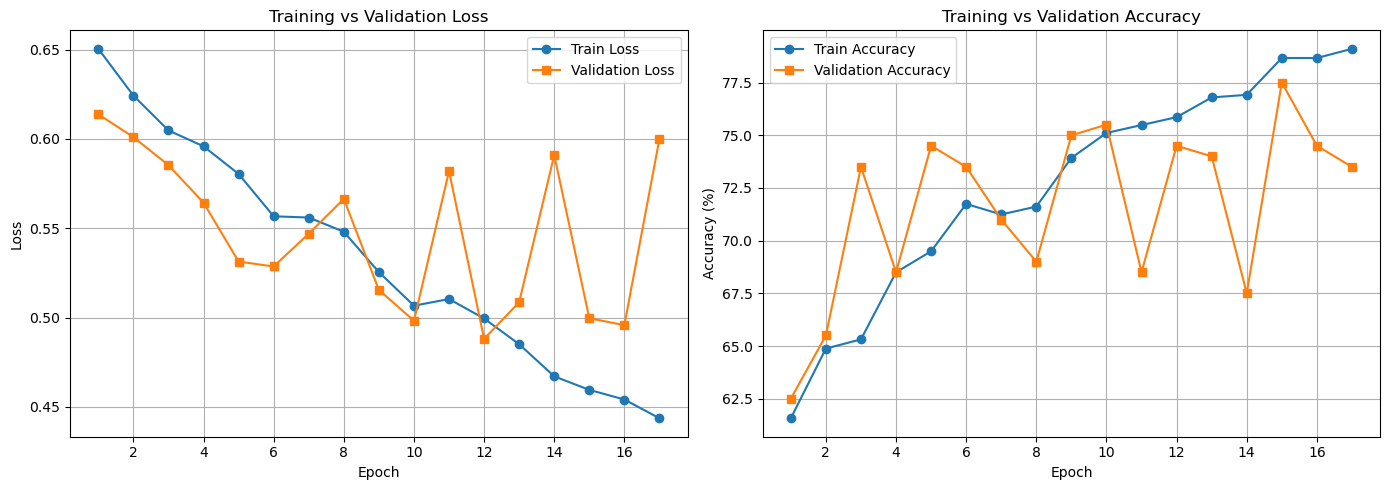

📊 Loss & Accuracy curves saved to: D:\luna16\loss_accuracy_curves.png


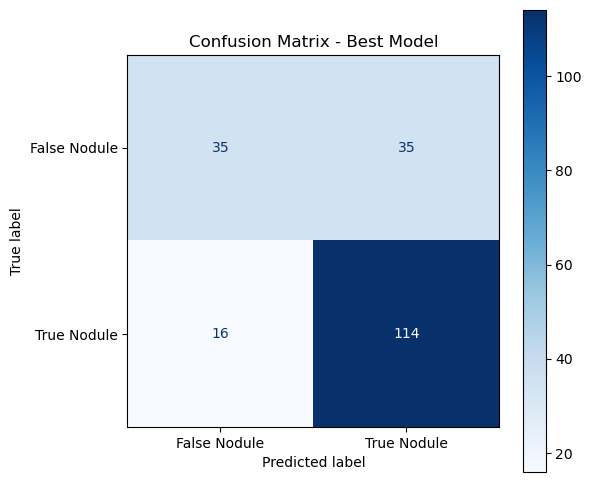

📊 Confusion matrix saved to: D:\luna16\confusion_matrix.png


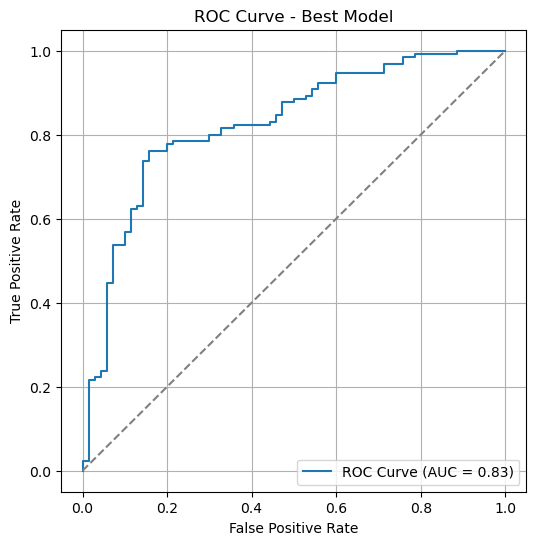

📊 ROC curve saved to: D:\luna16\roc_curve.png
✅ Final Validation Accuracy: 73.50%
✅ Final AUC Score: 0.8269


In [21]:
# 📈 Training Curves
epochs = range(1, len(train_losses) + 1)
plt.figure(figsize=(14, 5))

# 🔹 Loss Curve
plt.subplot(1, 2, 1)
plt.plot(epochs, train_losses, marker='o', label='Train Loss')
plt.plot(epochs, val_losses, marker='s', label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training vs Validation Loss')
plt.legend()
plt.grid(True)

# 🔸 Accuracy Curve
plt.subplot(1, 2, 2)
plt.plot(epochs, train_accuracies, marker='o', label='Train Accuracy')
plt.plot(epochs, val_accuracies, marker='s', label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.title('Training vs Validation Accuracy')
plt.legend()
plt.grid(True)

plt.tight_layout()
loss_acc_path = os.path.join(SAVE_DIR, "loss_accuracy_curves.png")
plt.savefig(loss_acc_path)
plt.show()

print(f"📊 Loss & Accuracy curves saved to: {loss_acc_path}")

# 📊 Confusion Matrix
cm = confusion_matrix(final_y_true, final_y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["False Nodule", "True Nodule"])
fig, ax = plt.subplots(figsize=(6, 6))
disp.plot(cmap='Blues', ax=ax, values_format='d')
plt.title('Confusion Matrix - Best Model')
plt.grid(False)

cm_path = os.path.join(SAVE_DIR, "confusion_matrix.png")
plt.savefig(cm_path)
plt.show()

print(f"📊 Confusion matrix saved to: {cm_path}")

# 📈 ROC Curve
fpr, tpr, _ = roc_curve(final_y_true, final_y_probs)
roc_auc = roc_auc_score(final_y_true, final_y_probs)

plt.figure(figsize=(6, 6))
plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Best Model')
plt.legend(loc='lower right')
plt.grid(True)

roc_path = os.path.join(SAVE_DIR, "roc_curve.png")
plt.savefig(roc_path)
plt.show()

print(f"📊 ROC curve saved to: {roc_path}")
print(f"✅ Final Validation Accuracy: {val_accuracies[-1]:.2f}%")
print(f"✅ Final AUC Score: {roc_auc:.4f}")


C:\Users\Adem Tounsi\AppData\Local\Temp\ipykernel_17652\3878085941.py:2: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(os.path.join(SAVE_DIR

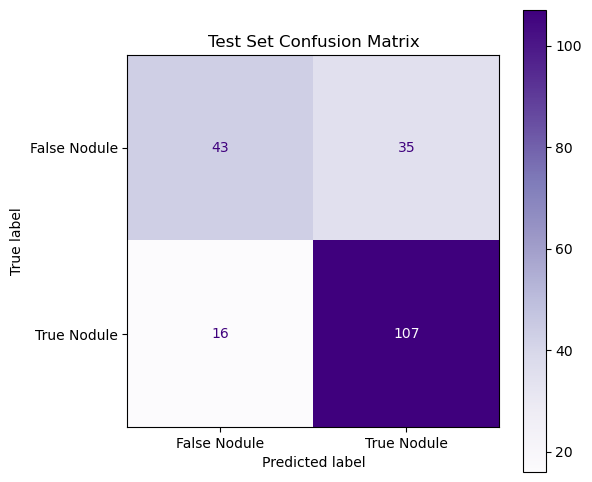

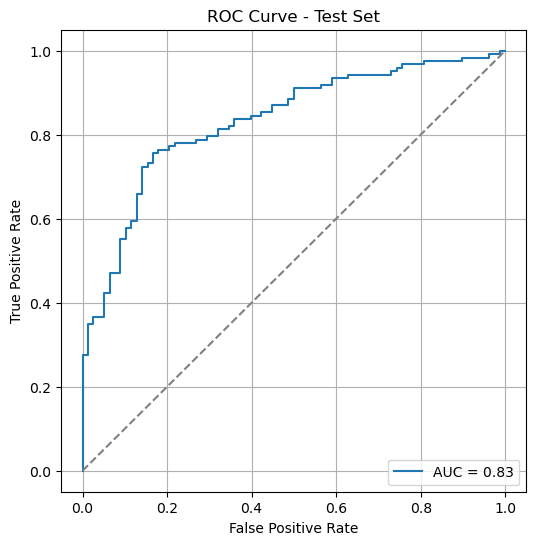

✅ Test Accuracy: 74.63%
✅ Test AUC Score: 0.8335


In [23]:
# 📦 Load best saved model
model.load_state_dict(torch.load(os.path.join(SAVE_DIR, "best_improved3dcnn_model.pth")))
model.to(device)
model.eval()

# 🧪 Evaluate on Test Set
test_y_true = []
test_y_pred = []
test_y_probs = []

with torch.no_grad():
    for test_x, test_y in test_loader:
        test_x, test_y = test_x.to(device), test_y.to(device)

        test_outputs = model(test_x)
        test_preds = test_outputs.argmax(dim=1)
        test_probs = torch.softmax(test_outputs, dim=1)[:, 1]

        test_y_true.extend(test_y.cpu().numpy())
        test_y_pred.extend(test_preds.cpu().numpy())
        test_y_probs.extend(test_probs.cpu().numpy())

# 🧮 Test Metrics
test_acc = accuracy_score(test_y_true, test_y_pred)
test_cm = confusion_matrix(test_y_true, test_y_pred)
test_auc = roc_auc_score(test_y_true, test_y_probs)

# 📊 Display Confusion Matrix
disp = ConfusionMatrixDisplay(confusion_matrix=test_cm, display_labels=["False Nodule", "True Nodule"])
fig, ax = plt.subplots(figsize=(6, 6))
disp.plot(cmap='Purples', ax=ax, values_format='d')
plt.title('Test Set Confusion Matrix')
plt.grid(False)
plt.savefig(os.path.join(SAVE_DIR, "test_confusion_matrix.png"))
plt.show()

# 📈 ROC Curve for Test
fpr, tpr, _ = roc_curve(test_y_true, test_y_probs)

plt.figure(figsize=(6, 6))
plt.plot(fpr, tpr, label=f'AUC = {test_auc:.2f}')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Test Set')
plt.legend(loc='lower right')
plt.grid(True)
plt.savefig(os.path.join(SAVE_DIR, "test_roc_curve.png"))
plt.show()

# ✅ Final report
print(f"✅ Test Accuracy: {test_acc * 100:.2f}%")
print(f"✅ Test AUC Score: {test_auc:.4f}")


In [34]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class ResidualBlock3D(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1):
        super(ResidualBlock3D, self).__init__()
        self.conv1 = nn.Conv3d(in_channels, out_channels, kernel_size=3, stride=stride, padding=1)
        self.bn1 = nn.BatchNorm3d(out_channels)
        self.conv2 = nn.Conv3d(out_channels, out_channels, kernel_size=3, stride=1, padding=1)
        self.bn2 = nn.BatchNorm3d(out_channels)

        self.shortcut = nn.Sequential()
        if stride != 1 or in_channels != out_channels:
            self.shortcut = nn.Sequential(
                nn.Conv3d(in_channels, out_channels, kernel_size=1, stride=stride),
                nn.BatchNorm3d(out_channels)
            )

    def forward(self, x):
        identity = self.shortcut(x)
        x = F.relu(self.bn1(self.conv1(x)))
        x = self.bn2(self.conv2(x))
        x += identity
        x = F.relu(x)
        return x

class ResNet3DLite(nn.Module):
    def __init__(self, num_classes=2):
        super(ResNet3DLite, self).__init__()
        self.layer0 = nn.Sequential(
            nn.Conv3d(1, 16, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm3d(16),
            nn.ReLU()
        )
        self.layer1 = self._make_layer(16, 32, stride=2)
        self.layer2 = self._make_layer(32, 64, stride=2)
        self.layer3 = self._make_layer(64, 128, stride=2)

        self.avgpool = nn.AdaptiveAvgPool3d((1,1,1))
        self.fc = nn.Linear(128, num_classes)

    def _make_layer(self, in_channels, out_channels, stride):
        return nn.Sequential(
            ResidualBlock3D(in_channels, out_channels, stride)
        )

    def forward(self, x):
        x = self.layer0(x)
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.avgpool(x)
        x = x.view(x.size(0), -1)
        x = self.fc(x)
        return x


In [35]:
import os
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, roc_curve, auc, roc_auc_score
import numpy as np
from tqdm import tqdm

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"✅ Using device: {device}")

model = ResNet3DLite(num_classes=2).to(device)

optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)
criterion = nn.CrossEntropyLoss()

SAVE_DIR = r"D:\luna16"
os.makedirs(SAVE_DIR, exist_ok=True)

num_epochs = 10
best_val_loss = float('inf')
patience = 3
early_stop_counter = 0

train_losses = []
val_losses = []
train_accuracies = []
val_accuracies = []

final_y_true = []
final_y_pred = []
final_y_probs = []


✅ Using device: cuda


In [36]:
for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    loop = tqdm(train_loader, desc=f"🔵 Epoch {epoch+1}/{num_epochs}", leave=True)

    for batch_x, batch_y in loop:
        batch_x, batch_y = batch_x.to(device), batch_y.to(device)

        optimizer.zero_grad()
        outputs = model(batch_x)
        loss = criterion(outputs, batch_y)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        preds = outputs.argmax(dim=1)
        correct += (preds == batch_y).sum().item()
        total += batch_y.size(0)

        loop.set_postfix({
            'loss': running_loss / (total / batch_x.size(0)),
            'acc': 100. * correct / total
        })

    avg_train_loss = running_loss / len(train_loader)
    avg_train_acc = 100. * correct / total

    train_losses.append(avg_train_loss)
    train_accuracies.append(avg_train_acc)

    # 📋 Validation
    model.eval()
    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    temp_y_true = []
    temp_y_pred = []
    temp_y_probs = []

    with torch.no_grad():
        for val_x, val_y in val_loader:
            val_x, val_y = val_x.to(device), val_y.to(device)

            val_outputs = model(val_x)
            val_loss = criterion(val_outputs, val_y)

            val_running_loss += val_loss.item()

            val_preds = val_outputs.argmax(dim=1)
            val_correct += (val_preds == val_y).sum().item()
            val_total += val_y.size(0)

            temp_y_true.extend(val_y.cpu().numpy())
            temp_y_pred.extend(val_preds.cpu().numpy())
            probs = torch.softmax(val_outputs, dim=1)[:,1]
            temp_y_probs.extend(probs.cpu().numpy())

    avg_val_loss = val_running_loss / len(val_loader)
    avg_val_acc = 100. * val_correct / val_total

    val_losses.append(avg_val_loss)
    val_accuracies.append(avg_val_acc)

    print(f"✅ Epoch [{epoch+1}/{num_epochs}] - Train Loss: {avg_train_loss:.4f} - Train Acc: {avg_train_acc:.2f}% | Val Loss: {avg_val_loss:.4f} - Val Acc: {avg_val_acc:.2f}%")

    # 🔥 Save best model
    if avg_val_loss < best_val_loss:
        best_val_loss = avg_val_loss
        early_stop_counter = 0
        torch.save(model.state_dict(), os.path.join(SAVE_DIR, "best_resnet3dlite_model.pth"))
        print("💾 Best model saved!")

        final_y_true = temp_y_true
        final_y_pred = temp_y_pred
        final_y_probs = temp_y_probs

    else:
        early_stop_counter += 1
        print(f"⏳ Early stop patience: {early_stop_counter}/{patience}")

    if early_stop_counter >= patience:
        print("🚨 Early stopping triggered.")
        break


🔵 Epoch 1/10:   0%|                                                                           | 0/101 [00:00<?, ?it/s]C:\Users\Adem Tounsi\AppData\Local\Temp\ipykernel_24568\1230563790.py:16: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue 

✅ Epoch [1/10] - Train Loss: 0.6571 - Train Acc: 61.76% | Val Loss: 0.6230 - Val Acc: 65.84%
💾 Best model saved!


🔵 Epoch 2/10: 100%|███████████████████████████████████████████| 101/101 [07:09<00:00,  4.25s/it, loss=0.117, acc=64.9]


✅ Epoch [2/10] - Train Loss: 0.6189 - Train Acc: 64.88% | Val Loss: 0.6848 - Val Acc: 64.84%
⏳ Early stop patience: 1/3


🔵 Epoch 3/10: 100%|███████████████████████████████████████████| 101/101 [07:13<00:00,  4.29s/it, loss=0.113, acc=68.1]


...

✅ Epoch [4/10] - Train Loss: 0.5862 - Train Acc: 67.00% | Val Loss: 0.5890 - Val Acc: 66.83%
⏳ Early stop patience: 1/3


🔵 Epoch 5/10: 100%|█████████████████████████████████████████████| 101/101 [07:17<00:00,  4.33s/it, loss=0.105, acc=71]


✅ Epoch [5/10] - Train Loss: 0.5550 - Train Acc: 70.99% | Val Loss: 0.6234 - Val Acc: 68.08%
⏳ Early stop patience: 2/3


🔵 Epoch 6/10: 100%|███████████████████████████████████████████| 101/101 [07:14<00:00,  4.31s/it, loss=0.104, acc=71.2]


✅ Epoch [6/10] - Train Loss: 0.5484 - Train Acc: 71.18% | Val Loss: 0.6166 - Val Acc: 65.84%
⏳ Early stop patience: 3/3
🚨 Early stopping triggered.


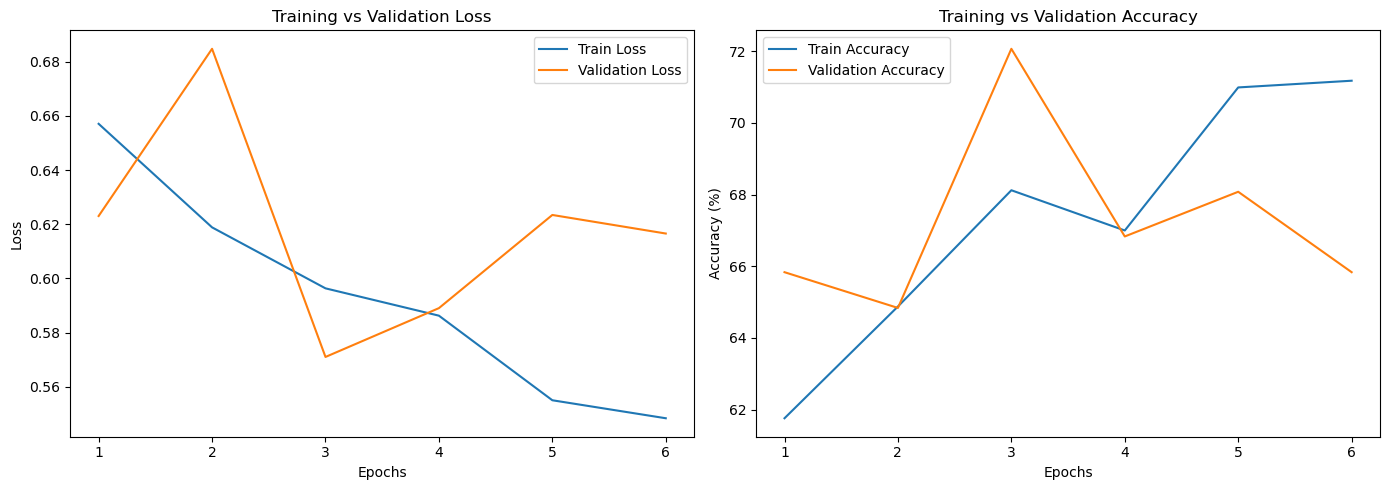

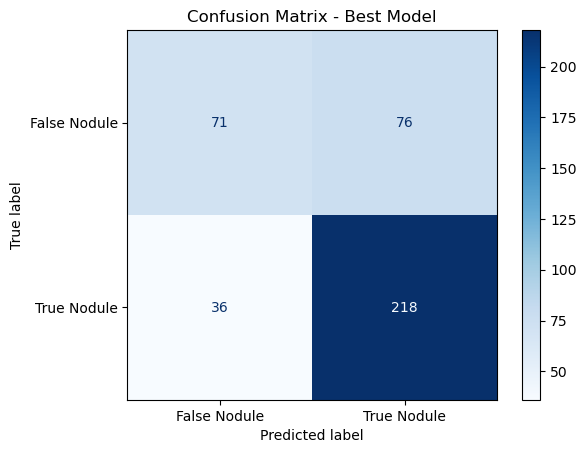

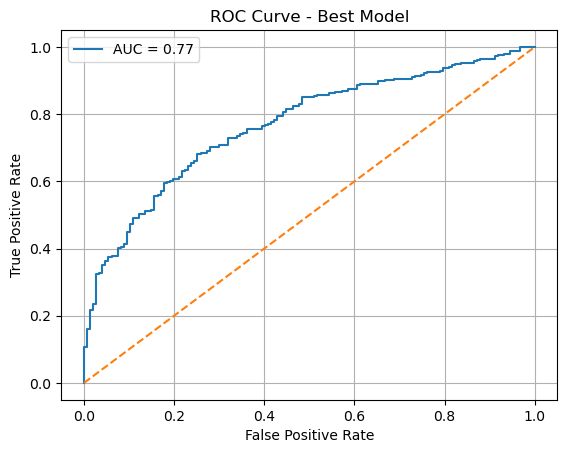

✅ Final Validation Accuracy: 65.84%
✅ Final AUC Score: 0.7678


In [37]:
# 📈 Loss and Accuracy curves
epochs = range(1, len(train_losses) + 1)

plt.figure(figsize=(14,5))
plt.subplot(1,2,1)
plt.plot(epochs, train_losses, label='Train Loss')
plt.plot(epochs, val_losses, label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Training vs Validation Loss')
plt.legend()

plt.subplot(1,2,2)
plt.plot(epochs, train_accuracies, label='Train Accuracy')
plt.plot(epochs, val_accuracies, label='Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy (%)')
plt.title('Training vs Validation Accuracy')
plt.legend()

plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, "loss_accuracy_curves.png"))
plt.show()

# 📈 Confusion Matrix
cm = confusion_matrix(final_y_true, final_y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["False Nodule", "True Nodule"])
disp.plot(cmap='Blues')
plt.title('Confusion Matrix - Best Model')
plt.grid(False)
plt.savefig(os.path.join(SAVE_DIR, "confusion_matrix.png"))
plt.show()

# 📈 ROC Curve
fpr, tpr, _ = roc_curve(final_y_true, final_y_probs)
roc_auc = roc_auc_score(final_y_true, final_y_probs)

plt.figure()
plt.plot(fpr, tpr, label=f'AUC = {roc_auc:.2f}')
plt.plot([0,1], [0,1], linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Best Model')
plt.legend()
plt.grid()
plt.savefig(os.path.join(SAVE_DIR, "roc_curve.png"))
plt.show()

print(f"✅ Final Validation Accuracy: {val_accuracies[-1]:.2f}%")
print(f"✅ Final AUC Score: {roc_auc:.4f}")


In [45]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class UNet3DEncoder(nn.Module):
    def __init__(self, in_channels=1, features=[32, 64, 128, 256]):
        super(UNet3DEncoder, self).__init__()
        self.encoders = nn.ModuleList()
        self.pools = nn.ModuleList()

        for feature in features:
            self.encoders.append(nn.Sequential(
                nn.Conv3d(in_channels, feature, kernel_size=3, padding=1),
                nn.BatchNorm3d(feature),
                nn.ReLU(inplace=True),
                nn.Conv3d(feature, feature, kernel_size=3, padding=1),
                nn.BatchNorm3d(feature),
                nn.ReLU(inplace=True),
                nn.Dropout3d(p=0.3)
            ))
            self.pools.append(nn.MaxPool3d(kernel_size=2, stride=2))
            in_channels = feature

    def forward(self, x):
        for encoder, pool in zip(self.encoders, self.pools):
            x = encoder(x)
            x = pool(x)
        return x  # Last deep feature


In [49]:
class UNet3DClassifier(nn.Module):
    def __init__(self, num_classes=2):
        super(UNet3DClassifier, self).__init__()
        self.encoder = UNet3DEncoder()

        self.global_pool = nn.AdaptiveAvgPool3d((1, 1, 1))
        self.dropout = nn.Dropout(p=0.4)

        self.classifier = nn.Sequential(
            nn.Linear(256, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(p=0.3),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.encoder(x)
        x = self.global_pool(x)
        x = torch.flatten(x, 1)
        x = self.classifier(x)
        return x


In [51]:
# 📍 Device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"✅ Using device: {device}")

model = UNet3DClassifier(num_classes=2).to(device)

# ✅ Weighted loss if imbalance exists (optional)
# class_weights = torch.tensor([1.0, 2.0]).to(device)  # Adjust for imbalance
# criterion = nn.CrossEntropyLoss(weight=class_weights)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4, weight_decay=1e-5)

# 📉 LR Scheduler
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', patience=3, factor=0.5)

# 📂 Save dir
SAVE_DIR = r"D:\luna16"
os.makedirs(SAVE_DIR, exist_ok=True)

# 🗓️ Training params
num_epochs = 30
patience = 7
best_val_loss = float('inf')
early_stop_counter = 0

train_losses, val_losses = [], []
train_accuracies, val_accuracies = [], []

final_y_true, final_y_pred, final_y_probs = [], [], []


✅ Using device: cuda


In [53]:
for epoch in range(num_epochs):
    # 🔧 Training mode
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    loop = tqdm(train_loader, desc=f"🔵 Epoch {epoch+1}/{num_epochs}", leave=True)

    for batch_x, batch_y in loop:
        batch_x, batch_y = batch_x.to(device), batch_y.to(device)

        optimizer.zero_grad()
        outputs = model(batch_x)
        loss = criterion(outputs, batch_y)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * batch_x.size(0)
        preds = outputs.argmax(dim=1)
        correct += (preds == batch_y).sum().item()
        total += batch_y.size(0)

        loop.set_postfix({
            'loss': f"{running_loss / total:.4f}",
            'acc': f"{(100. * correct / total):.2f}%"
        })

    avg_train_loss = running_loss / total
    avg_train_acc = 100. * correct / total
    train_losses.append(avg_train_loss)
    train_accuracies.append(avg_train_acc)

    # 📋 Validation mode
    model.eval()
    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    temp_y_true = []
    temp_y_pred = []
    temp_y_probs = []

    with torch.no_grad():
        for val_x, val_y in val_loader:
            val_x, val_y = val_x.to(device), val_y.to(device)
            val_outputs = model(val_x)
            val_loss = criterion(val_outputs, val_y)

            val_running_loss += val_loss.item() * val_x.size(0)
            val_preds = val_outputs.argmax(dim=1)

            val_correct += (val_preds == val_y).sum().item()
            val_total += val_y.size(0)

            temp_y_true.extend(val_y.cpu().numpy())
            temp_y_pred.extend(val_preds.cpu().numpy())
            probs = torch.softmax(val_outputs, dim=1)[:, 1]
            temp_y_probs.extend(probs.cpu().numpy())

    avg_val_loss = val_running_loss / val_total
    avg_val_acc = 100. * val_correct / val_total

    val_losses.append(avg_val_loss)
    val_accuracies.append(avg_val_acc)

    print(f"\n✅ Epoch {epoch+1}/{num_epochs} - "
          f"Train Loss: {avg_train_loss:.4f} | Train Acc: {avg_train_acc:.2f}% || "
          f"Val Loss: {avg_val_loss:.4f} | Val Acc: {avg_val_acc:.2f}%")

    # 💾 Save best model
    if avg_val_loss < best_val_loss:
        best_val_loss = avg_val_loss
        early_stop_counter = 0
        model_path = os.path.join(SAVE_DIR, "best_unet3dclassifier_model.pth")
        torch.save(model.state_dict(), model_path)
        print(f"💾 Best model saved to {model_path}")

        final_y_true = temp_y_true
        final_y_pred = temp_y_pred
        final_y_probs = temp_y_probs
    else:
        early_stop_counter += 1
        print(f"⏳ Early stopping counter: {early_stop_counter}/{patience}")

    if early_stop_counter >= patience:
        print("🚨 Early stopping triggered.")
        break


🔵 Epoch 1/30:   0%|                                                                           | 0/101 [00:00<?, ?it/s]C:\Users\Adem Tounsi\AppData\Local\Temp\ipykernel_17652\1230563790.py:16: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue 


✅ Epoch 1/30 - Train Loss: 0.7304 | Train Acc: 52.34% || Val Loss: 0.6420 | Val Acc: 66.00%
💾 Best model saved to D:\luna16\best_unet3dclassifier_model.pth


🔵 Epoch 2/30: 100%|████████████████████████████████████████| 101/101 [02:40<00:00,  1.59s/it, loss=0.6926, acc=55.02%]



✅ Epoch 2/30 - Train Loss: 0.6926 | Train Acc: 55.02% || Val Loss: 0.6670 | Val Acc: 54.00%
⏳ Early stopping counter: 1/7


🔵 Epoch 3/30: 100%|████████████████████████████████████████| 101/101 [02:40<00:00,  1.59s/it, loss=0.6909, acc=57.95%]


...


✅ Epoch 28/30 - Train Loss: 0.5544 | Train Acc: 71.30% || Val Loss: 0.5069 | Val Acc: 73.50%
⏳ Early stopping counter: 1/7


🔵 Epoch 29/30: 100%|███████████████████████████████████████| 101/101 [02:54<00:00,  1.72s/it, loss=0.5440, acc=71.87%]



✅ Epoch 29/30 - Train Loss: 0.5440 | Train Acc: 71.87% || Val Loss: 0.5074 | Val Acc: 74.50%
⏳ Early stopping counter: 2/7


🔵 Epoch 30/30: 100%|███████████████████████████████████████| 101/101 [02:54<00:00,  1.73s/it, loss=0.5393, acc=72.30%]



✅ Epoch 30/30 - Train Loss: 0.5393 | Train Acc: 72.30% || Val Loss: 0.5299 | Val Acc: 75.00%
⏳ Early stopping counter: 3/7


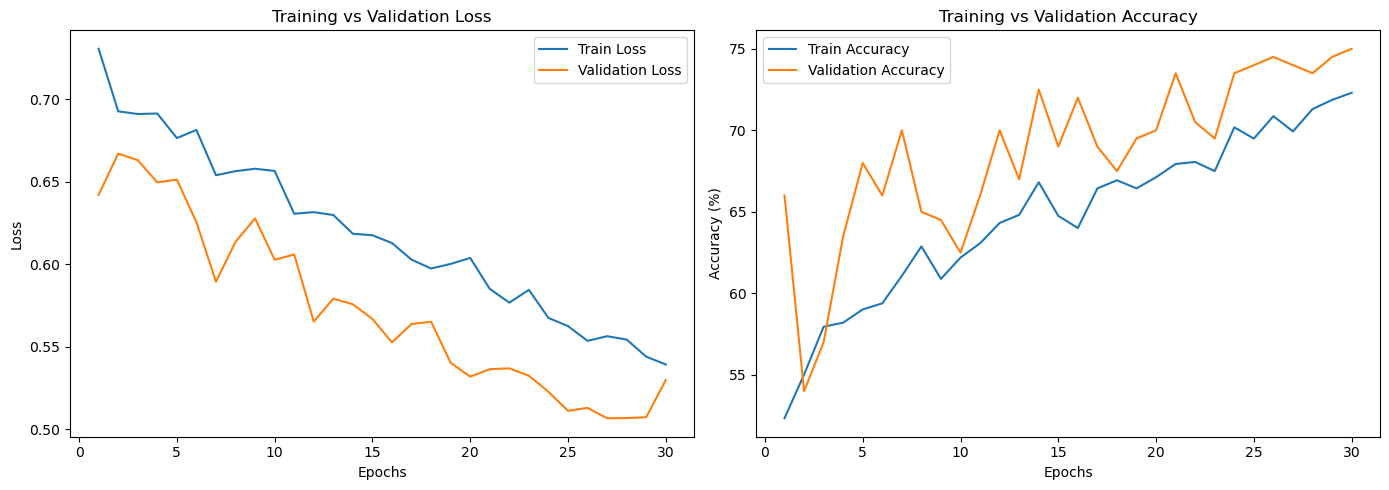

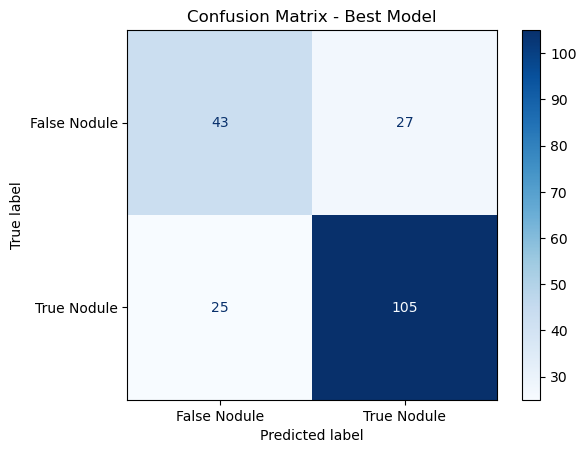

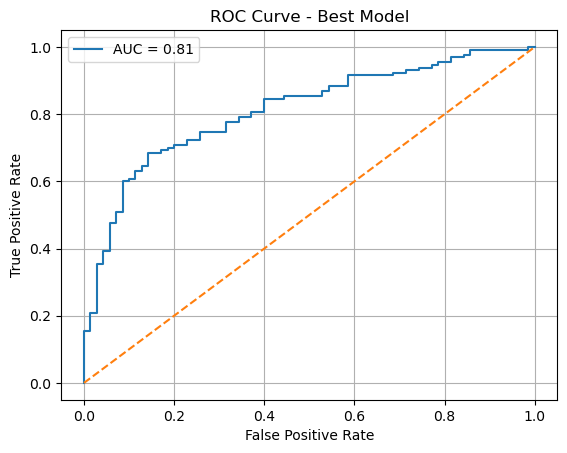

✅ Final Validation Accuracy: 75.00%
✅ Final AUC Score: 0.8116


In [55]:
# 📈 Loss and Accuracy curves
epochs = range(1, len(train_losses) + 1)

plt.figure(figsize=(14,5))
plt.subplot(1,2,1)
plt.plot(epochs, train_losses, label='Train Loss')
plt.plot(epochs, val_losses, label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Training vs Validation Loss')
plt.legend()

plt.subplot(1,2,2)
plt.plot(epochs, train_accuracies, label='Train Accuracy')
plt.plot(epochs, val_accuracies, label='Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy (%)')
plt.title('Training vs Validation Accuracy')
plt.legend()

plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, "loss_accuracy_curves.png"))
plt.show()

# 📈 Confusion Matrix
cm = confusion_matrix(final_y_true, final_y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["False Nodule", "True Nodule"])
disp.plot(cmap='Blues')
plt.title('Confusion Matrix - Best Model')
plt.grid(False)
plt.savefig(os.path.join(SAVE_DIR, "confusion_matrix.png"))
plt.show()

# 📈 ROC Curve
fpr, tpr, _ = roc_curve(final_y_true, final_y_probs)
roc_auc = roc_auc_score(final_y_true, final_y_probs)

plt.figure()
plt.plot(fpr, tpr, label=f'AUC = {roc_auc:.2f}')
plt.plot([0,1], [0,1], linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Best Model')
plt.legend()
plt.grid()
plt.savefig(os.path.join(SAVE_DIR, "roc_curve.png"))
plt.show()

print(f"✅ Final Validation Accuracy: {val_accuracies[-1]:.2f}%")
print(f"✅ Final AUC Score: {roc_auc:.4f}")
